# Week 5: Train and compare two models

To start, save a copy to your Drive (File → Save a copy in Drive), then run the cells in order. The training and the images run on Replicate, so Colab's free CPU runtime is enough. You will need the course Replicate token, which the instructor shares in the first studio. Add it in Colab's Secrets panel (the key icon on the left) with the name REPLICATE_API_TOKEN, and turn on Notebook access. The outputs below are from the 56 museum chairs, trained once with automatic captions and once with captions from the museum records.

## 1. Setup

This reads your Replicate token from Colab's Secrets and checks it with Replicate. If the token is not in Secrets, it will ask you to paste it.

In [1]:
import csv, hashlib, io, json, os, sys, tarfile, textwrap, time, zipfile
IN_COLAB = "google.colab" in sys.modules
import requests
from PIL import Image, ImageDraw, ImageFont, ImageOps
from IPython.display import display

token = os.environ.get("REPLICATE_API_TOKEN")
if IN_COLAB and not token:
    from google.colab import userdata
    try:
        token = userdata.get("REPLICATE_API_TOKEN")
    except Exception:  # not in Secrets, or Notebook access is off
        token = None
if not token:
    import getpass
    token = getpass.getpass("Replicate token: ")
API = "https://api.replicate.com/v1"
HEADERS = {"Authorization": f"Bearer {token.strip()}"}
r = requests.get(f"{API}/account", headers=HEADERS, timeout=60)
assert r.ok, "Replicate did not accept this token. Check that it is the course Replicate token, with nothing before or after it."
owner = r.json()["username"]
EXAMPLE = "https://raw.githubusercontent.com/chuanenlin/mlfordesign/main/examples/museum-chairs/"
TRAINER = "ostris/flux-dev-lora-trainer"
H100_PER_SECOND = 0.001525  # Replicate's price for the H100 GPU that the training and the images run on (replicate.com/pricing)
print("ready")

ready


## 2. Your images

With USE_EXAMPLE = True, it downloads the 56 museum chairs and writes a caption for each from its museum record, for example "a photo of MUSCHR, turned armchair, American, 1650–1700". To use your own, set it to False and run the cell again, and it will ask for a zip of your 20 to 40 images. Change TRIGGER to a made-up word for your set. If you want to compare captions, put your captions in the zip too, either as the captions.csv from week 4 or as a .txt file with the same name as each image. A caption without your trigger word gets "a photo of" and the trigger word added at the start. Photos larger than 1024 pixels on a side are resized to 1024 pixels before the upload.

56 images, 56 with your own captions


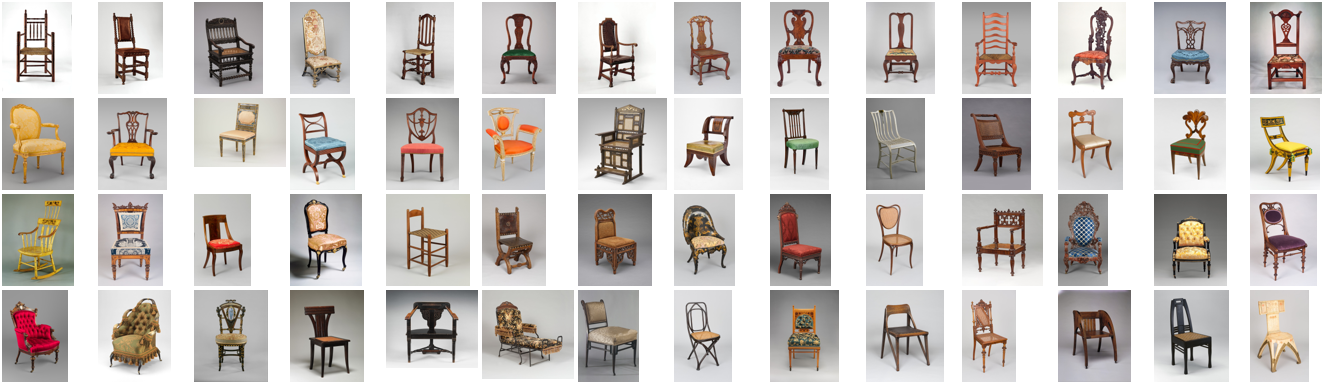

In [2]:
USE_EXAMPLE = True  # True: the 56 museum chairs. False: upload a zip of 20 to 40 of your own images.
TRIGGER = "MUSCHR"  # a made-up word for your set, which goes in every caption and every prompt

def stem(name):
    return os.path.splitext(os.path.basename(name))[0]

own_captions, skipped = {}, []
if USE_EXAMPLE:
    records = list(csv.DictReader(io.StringIO(requests.get(EXAMPLE + "credits.csv", timeout=60).content.decode("utf-8"))))
    images = {r["file"]: requests.get(EXAMPLE + "train/" + r["file"], timeout=60).content for r in records}
    # Captions written from each chair's museum record: its title, maker and date.
    own_captions = {r["file"]: f"a photo of {TRIGGER}, {r['title'].lower()}, {r['maker']}, {r['date']}" for r in records}
else:
    from google.colab import files
    z = zipfile.ZipFile(io.BytesIO(next(iter(files.upload().values()))))
    names = [n for n in z.namelist() if not n.endswith("/") and not os.path.basename(n).startswith(".")]
    images, texts = {}, {}
    for n in names:
        ext = os.path.splitext(n)[1].lower()
        if ext in (".jpg", ".jpeg", ".png", ".webp"):
            # Phone photos are turned upright and made at most 1024 pixels on a side, which is what the trainer uses.
            im = ImageOps.exif_transpose(Image.open(io.BytesIO(z.read(n)))).convert("RGB")
            im.thumbnail((1024, 1024))
            buf = io.BytesIO(); im.save(buf, "JPEG", quality=92)
            images[stem(n) + ".jpg"] = buf.getvalue()
        elif ext == ".txt":  # a caption file with the same name as its image
            texts[stem(n)] = z.read(n).decode("utf-8-sig")
        elif ext == ".csv":  # or the captions.csv from week 4, with the columns file and caption
            for row in csv.DictReader(io.StringIO(z.read(n).decode("utf-8-sig"))):
                texts[stem(row["file"])] = row["caption"]
        else:
            skipped.append(os.path.basename(n))
    for f in images:
        c = texts.get(stem(f), "").strip()
        if c:  # every caption starts with the trigger word, as in the example
            own_captions[f] = c if TRIGGER in c else f"a photo of {TRIGGER}, {c}"

def sheet(pics, size=96, cols=14):
    out = Image.new("RGB", (cols * size, -(-len(pics) // cols) * size), "white")
    for i, p in enumerate(pics):
        im = Image.open(io.BytesIO(p)).convert("RGB"); im.thumbnail((size - 4, size - 4))
        out.paste(im, ((i % cols) * size + 2, (i // cols) * size + 2))
    return out

print(len(images), "images,", len(own_captions), "with your own captions")
if skipped:
    print("Skipped (not an image or a caption):", ", ".join(skipped))
display(sheet(list(images.values())))

## 3. The one thing you change

Set SETTING to "captions", "steps" or "rank", and the two models will differ only in that. With "captions", model A gets captions that the trainer writes automatically and model B gets yours. With "steps", A trains for 500 steps and B for 1,000. With "rank", A has rank 4 and B has rank 16 (the rank is the size of the LoRA, as in the week 5 slides).

In [3]:
SETTING = "captions"  # "captions", "steps" or "rank"

# A and B differ only in SETTING. Everything else stays the same: 1,000 steps, rank 16, the same images.
CHOICES = {"captions": ("automatic", "your own"), "steps": (500, 1000), "rank": (4, 16)}
A, B = CHOICES[SETTING]

def settings(value):
    s = {"trigger_word": TRIGGER, "steps": 1000, "lora_rank": 16,
         "autocaption": True, "autocaption_prefix": f"a photo of {TRIGGER}, "}
    if SETTING == "captions" and value == "your own":
        s["autocaption"] = False
    if SETTING == "steps":
        s["steps"] = value
    if SETTING == "rank":
        s["lora_rank"] = value
    return s

if SETTING == "captions":
    missing = [f for f in images if f not in own_captions]
    assert not missing, (f"No caption for {len(missing)} images, for example {missing[:3]}. Add a .txt file with the same "
                         "name as each image to the zip, or the captions.csv from week 4.")
    for f in list(images)[:3]:
        print(f, "->", own_captions[f])
print("A:", SETTING, "=", A, " | B:", SETTING, "=", B)

met-146.jpg -> a photo of MUSCHR, turned armchair, American, 1650–1700
met-1540.jpg -> a photo of MUSCHR, side chair, American, 1675–1700
aic-272056.jpg -> a photo of MUSCHR, armchair, Coromandel Coast, probably Madras (Chennai), India, c. 1690–1700
A: captions = automatic  | B: captions = your own


## 4. Train both models

It uploads your images and trains both models on Replicate at the same time, with the trainer ostris/flux-dev-lora-trainer. For the museum chairs, each training took 11 to 12 minutes and cost about 1 US dollar. The example's two trainings are already done, so with USE_EXAMPLE = True this cell reuses them (set TRAIN_EXAMPLE = True to train them again). Each training is saved in trainings.json as soon as it starts, so if the cell stops or you run it again, it waits for the same trainings and does not pay for them twice. At the end, it prints the LoRA link of each model and saves both in lora-links.txt. Keep the link of the model you pick. The slider notebook and the week 6 tool notebook ask for it.

In [4]:
TRAIN_EXAMPLE = False  # the example's two trainings (SETTING = "captions") are done already, so they are reused

def training_key(value):
    """The same key means the same images, captions, trigger word and settings, so a finished training can be reused."""
    s = settings(value)
    h = hashlib.sha1(json.dumps(s, sort_keys=True).encode())
    for f in sorted(images):
        h.update(f.encode() + hashlib.sha1(images[f]).digest())
        if not s["autocaption"]:
            h.update(own_captions[f].encode())
    return f"{SETTING}={value}, set {h.hexdigest()[:8]}"

def make_zip(with_captions):
    buf = io.BytesIO()
    with zipfile.ZipFile(buf, "w") as z:
        for name, data in images.items():
            z.writestr(name, data)
            if with_captions:
                z.writestr(stem(name) + ".txt", own_captions[name])
    return buf.getvalue()

def upload(data, filename):
    r = requests.post(f"{API}/files", headers=HEADERS, files={"content": (filename, data, "application/zip")}, timeout=600)
    r.raise_for_status()
    return r.json()["urls"]["get"]

def model_for(key):
    # One model per set and setting, so students who share the course token never write to the same model.
    name = "mlfd-week5-" + key.split(", set ")[1] + "-" + key.split(",")[0].replace("=", "-").replace(" ", "-")
    if requests.get(f"{API}/models/{owner}/{name}", headers=HEADERS, timeout=60).status_code == 404:
        requests.post(f"{API}/models", headers=HEADERS, timeout=60,
                      json={"owner": owner, "name": name, "visibility": "private", "hardware": "gpu-h100"}).raise_for_status()
    return f"{owner}/{name}"

def save():
    json.dump(jobs, open("trainings.json", "w"), indent=1)

# trainings.json keeps every training as soon as it starts, so running this cell again picks them up instead of paying twice.
jobs = json.load(open("trainings.json")) if os.path.exists("trainings.json") else {}
if USE_EXAMPLE and not TRAIN_EXAMPLE:
    jobs.update(requests.get(EXAMPLE + "trainings.json", timeout=60).json())
version = None
for label, value in (("A", A), ("B", B)):
    key = training_key(value)
    status = jobs.get(key, {}).get("status")
    if status in ("succeeded", "starting", "processing"):
        print(label, "uses the training that", "finished" if status == "succeeded" else "is still running", "for", key)
        continue
    assert not (USE_EXAMPLE and not TRAIN_EXAMPLE), ('The example has trainings only for SETTING = "captions". Set '
                                                     "TRAIN_EXAMPLE = True to train the museum chairs with this setting.")
    if status:
        print(label, "the last training for", key, "ended as", status, "- starting it again")
    version = version or requests.get(f"{API}/models/{TRAINER}", headers=HEADERS, timeout=60).json()["latest_version"]["id"]
    url = upload(make_zip(SETTING == "captions" and value == "your own"), f"set-{label}.zip")
    r = requests.post(f"{API}/models/{TRAINER}/versions/{version}/trainings", headers=HEADERS, timeout=60,
                      json={"destination": model_for(key), "input": {"input_images": url, **settings(value)}})
    assert r.ok, r.text
    jobs[key] = r.json(); save()
    print(label, "started:", key)

keys = [training_key(A), training_key(B)]
t0, last = time.time(), ""
while any(jobs[k]["status"] not in ("succeeded", "failed", "canceled") for k in keys):
    time.sleep(30)
    for k in keys:
        if jobs[k]["status"] not in ("succeeded", "failed", "canceled"):
            jobs[k] = requests.get(jobs[k]["urls"]["get"], headers=HEADERS, timeout=60).json(); save()
    now = ", ".join(f"{k.split(',')[0]}: {jobs[k]['status']}" for k in keys)
    if now != last:
        print(f"{round((time.time() - t0) / 60)} min  {now}"); last = now

links = []
for label, value, k in (("A", A, keys[0]), ("B", B, keys[1])):
    j = jobs[k]
    assert j["status"] == "succeeded", f"{label} {j['status']}: {j.get('error')}"
    secs = j["metrics"]["predict_time"]
    print(f"{label} ({SETTING} = {value}): {secs / 60:.0f} min of training, about ${secs * H100_PER_SECOND:.2f}")
    links.append(f"{label} ({SETTING} = {value}): {j['output']['weights']}")
open("lora-links.txt", "w").write("\n".join(links) + "\n")
print("\nLoRA links, also saved in lora-links.txt:")
print("\n".join(links))

A uses the training that finished for captions=automatic, set bff80284
B uses the training that finished for captions=your own, set 9565ded3
A (captions = automatic): 12 min of training, about $1.11
B (captions = your own): 11 min of training, about $1.00

LoRA links, also saved in lora-links.txt:
A (captions = automatic): https://replicate.delivery/xezq/Xpt8jJMSTTbsAJl8bIfbw3dfFimwOEDPvzx5w1efZbbzxIGeC/trained_model.tar
B (captions = your own): https://replicate.delivery/xezq/B3h24veFzfrflp3dC8WNrX3bwxEJqoYFgrgFlFbMX9H6WEDvA/trained_model.tar


## 5. The automatic captions

The trainer keeps the captions it wrote inside model A's LoRA file. This cell reads them and shows three of them next to your own. For the museum chairs, 20 of the 56 automatic captions start with "A photo of" and do not have MUSCHR in them. Check whether yours have your trigger word, and whether they describe the shape, the material and the details of your designs.

56 automatic captions, 20 of them without MUSCHR


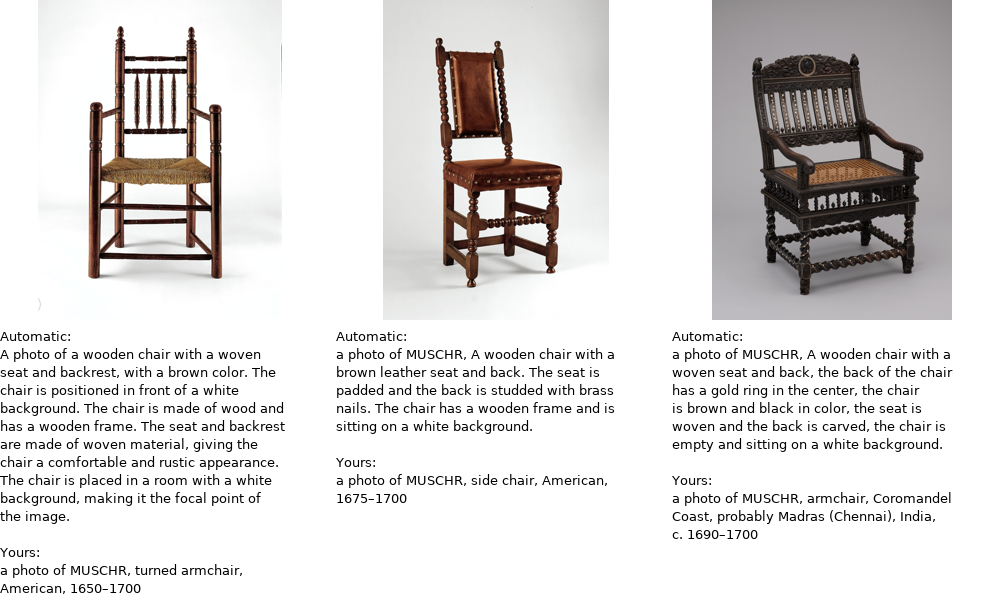

In [5]:
# The trainer keeps the captions it wrote inside model A's LoRA file, in a folder called captions.
data = requests.get(jobs[keys[0]]["output"]["weights"], timeout=600).content
with tarfile.open(fileobj=io.BytesIO(data)) as t:
    auto = {stem(m.name): t.extractfile(m).read().decode("utf-8").strip()
            for m in t.getmembers() if m.isfile() and "/captions/" in m.name}
no_trigger = [f for f in auto if TRIGGER not in auto[f]]
print(f"{len(auto)} automatic captions, {len(no_trigger)} of them without {TRIGGER}")

from matplotlib import font_manager
FONT = font_manager.findfont("DejaVu Sans")  # has every character in the museum records, such as the dash in 1650–1700

def caption_card(f, w=320):
    im = Image.open(io.BytesIO(images[f])).convert("RGB"); im.thumbnail((w, w))
    lines = ["Automatic:"] + textwrap.wrap(auto.get(stem(f), "(none)"), 42)
    if f in own_captions:
        lines += ["", "Yours:"] + textwrap.wrap(own_captions[f], 42)
    font = ImageFont.truetype(FONT, 13)
    out = Image.new("RGB", (w, w + 12 + 18 * len(lines)), "white")
    out.paste(im, ((w - im.width) // 2, 0))
    for i, line in enumerate(lines):
        ImageDraw.Draw(out).text((0, w + 8 + 18 * i), line, fill="black", font=font)
    return out

cards = [caption_card(f) for f in list(images)[:3]]
row3 = Image.new("RGB", (sum(c.width + 16 for c in cards), max(c.height for c in cards)), "white")
for i, c in enumerate(cards):
    row3.paste(c, (i * (c.width + 16), 0))
row3

## 6. The same seeds with both models

It makes four images with each model, with the same prompt and the same four seeds, so the only difference between the two rows is the setting you changed. Change PROMPT to describe your own designs, and keep your trigger word in it. For the museum chairs, the eight images took about 7 seconds each and cost about 0.09 US dollars in all. For the hand-in, download comparison.jpg from the Files panel on the left, and write a few sentences on which model's images look more like your designs (for example the shape, the material or the details), and why you think the setting made that difference.

prompt: a photo of MUSCHR, a side chair, museum object photograph on a plain grey backdrop | seeds: [1, 2, 3, 4]
8 images, about 7 seconds each, about $0.09 in all


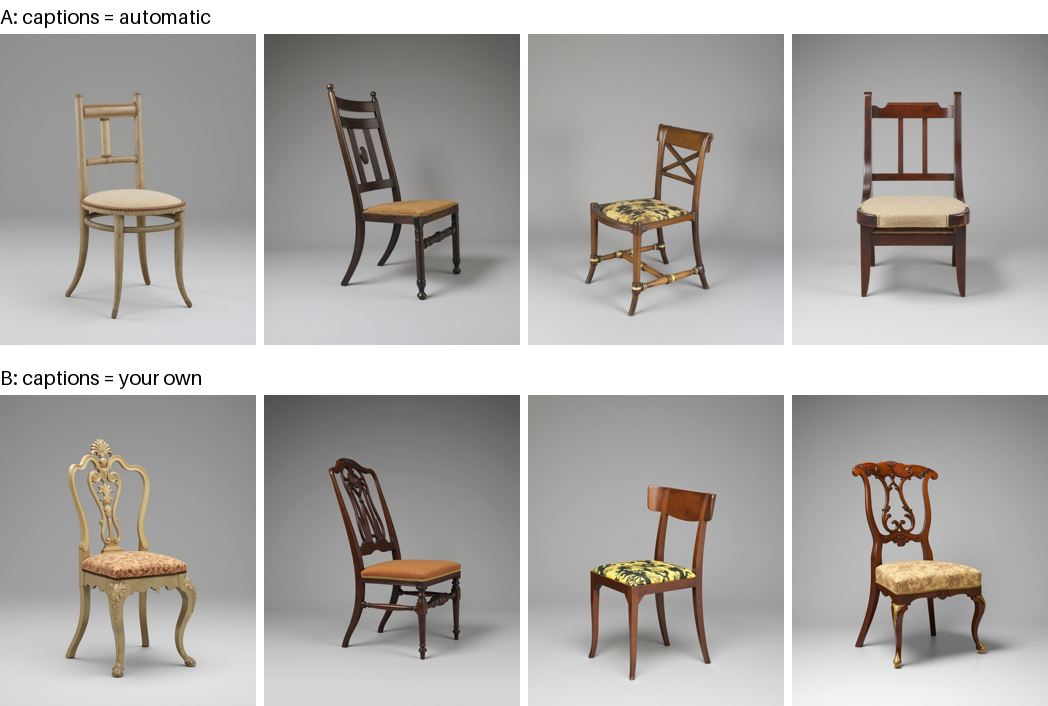

In [6]:
PROMPT = f"a photo of {TRIGGER}, a side chair, museum object photograph on a plain grey backdrop"
SEEDS = [1, 2, 3, 4]
times = []

def make_image(version, seed):
    """One image from a trained model, run directly by its version on Replicate."""
    inp = {"prompt": PROMPT, "seed": seed, "lora_scale": 1, "go_fast": False, "aspect_ratio": "4:5",
           "num_inference_steps": 28, "guidance_scale": 3, "output_format": "jpg"}
    r = requests.post(f"{API}/predictions", headers=HEADERS, json={"version": version, "input": inp}, timeout=300).json()
    while r.get("status") not in ("succeeded", "failed", "canceled"):
        time.sleep(2)
        r = requests.get(r["urls"]["get"], headers=HEADERS, timeout=60).json()
    if r["status"] != "succeeded":
        raise RuntimeError(r.get("error"))
    times.append(r["metrics"]["predict_time"])
    url = r["output"][0] if isinstance(r["output"], list) else r["output"]
    return Image.open(io.BytesIO(requests.get(url, timeout=120).content)).convert("RGB")

def row(pics, label, w=256):
    h = round(w * pics[0].height / pics[0].width)
    out = Image.new("RGB", (len(pics) * (w + 8) - 8, h + 34), "white")
    ImageDraw.Draw(out).text((0, 4), label, fill="black", font=ImageFont.load_default(20))
    for i, p in enumerate(pics):
        out.paste(p.resize((w, h)), (i * (w + 8), 34))
    return out

rows = []
for label, value, k in (("A", A, keys[0]), ("B", B, keys[1])):
    trained = jobs[k]["output"]["version"].split(":")[1]
    pics = [make_image(trained, s) for s in SEEDS]
    for s, p in zip(SEEDS, pics):
        p.save(f"{label}-seed-{s}.jpg")
    rows.append(row(pics, f"{label}: {SETTING} = {value}"))
both = Image.new("RGB", (rows[0].width, sum(r.height for r in rows) + 16), "white")
both.paste(rows[0], (0, 0)); both.paste(rows[1], (0, rows[0].height + 16))
both.save("comparison.jpg")
print("prompt:", PROMPT, "| seeds:", SEEDS)
print(f"{len(times)} images, about {sum(times) / len(times):.0f} seconds each, about ${sum(times) * H100_PER_SECOND:.2f} in all")
both

## 7. Both models on your map

It makes a map of your training images with CLIP, like the map in week 4, and puts each new image between its three closest training images, with a line to each of them. Model A's images are outlined in orange and model B's in green. Look at which of your designs each model's images land next to. CLIP runs on the CPU, so this takes a minute or two.

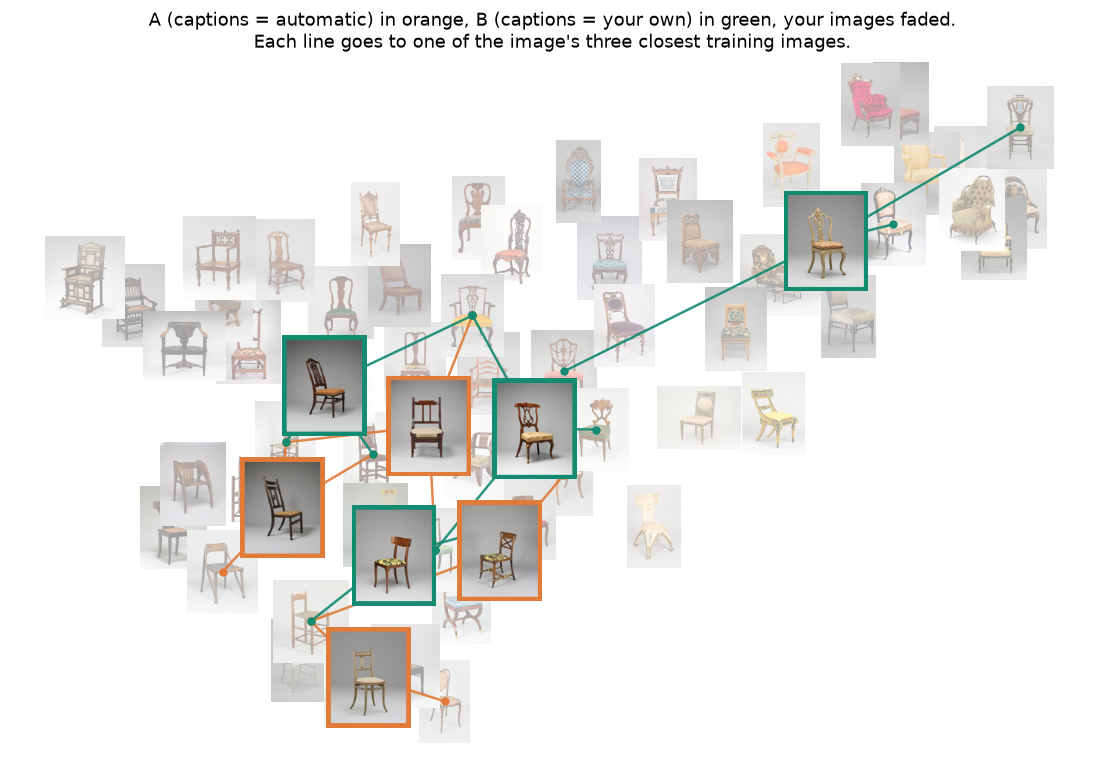

In [7]:
if IN_COLAB:
    !pip -q install umap-learn
import numpy as np, torch, umap
import matplotlib.pyplot as plt
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from transformers import CLIPModel, CLIPProcessor

dev = "cuda" if torch.cuda.is_available() else "cpu"
clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(dev).eval()
cproc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
train_pics = [Image.open(io.BytesIO(b)).convert("RGB") for b in images.values()]
made = {label: [Image.open(f"{label}-seed-{s}.jpg").convert("RGB") for s in SEEDS] for label in ("A", "B")}

def clip_embed(pics):
    out = []
    with torch.no_grad():
        for i in range(0, len(pics), 16):
            e = clip.get_image_features(**cproc(images=pics[i:i + 16], return_tensors="pt").to(dev))
            if not torch.is_tensor(e):  # newer versions of transformers return an object
                e = e.image_embeds if getattr(e, "image_embeds", None) is not None else e.pooler_output
                if e.shape[-1] != clip.config.projection_dim:
                    e = clip.visual_projection(e)
            out.append(torch.nn.functional.normalize(e, dim=-1).cpu().numpy())
    return np.concatenate(out)

CT = clip_embed(train_pics)
xy = umap.UMAP(n_neighbors=min(15, len(train_pics) - 1), min_dist=0.3, metric="cosine", random_state=0).fit_transform(CT)
# Each new image goes between its three closest training images by CLIP, and a line goes to each of the three.
near = {label: np.argsort(-(clip_embed(pics) @ CT.T), axis=1)[:, :3] for label, pics in made.items()}
COLORS = {"A": "#E07B39", "B": "#138A72"}

def thumb(ax, im, x, y, size=0.5, faded=False, border=None, z=1):
    im = im.copy(); im.thumbnail((120, 120))
    if faded:
        im = Image.blend(im, Image.new("RGB", im.size, "white"), 0.6)
    if border:
        im = ImageOps.expand(im, border=6, fill=border)
    box = AnnotationBbox(OffsetImage(np.asarray(im), zoom=size), (x, y), frameon=False, zorder=z)
    ax.add_artist(box)
    return box

fig, ax = plt.subplots(figsize=(14, 9))
pad = (xy.max(0) - xy.min(0)) * 0.08
ax.set_xlim(xy[:, 0].min() - pad[0], xy[:, 0].max() + pad[0])
ax.set_ylim(xy[:, 1].min() - pad[1], xy[:, 1].max() + pad[1])
ax.axis("off")
for (x, y), im in zip(xy, train_pics):
    thumb(ax, im, x, y, faded=True)
boxes = [(label, n, thumb(ax, im, *xy[near[label][n]].mean(0), size=0.55, border=COLORS[label], z=3))
         for label, pics in made.items() for n, im in enumerate(pics)]

# Move new images apart until none covers another, working in screen pixels.
fig.canvas.draw()
r = fig.canvas.get_renderer()
size = np.array([[b.get_window_extent(r).width, b.get_window_extent(r).height] for _, _, b in boxes]).max(0) + 8
pos = ax.transData.transform(np.array([b.xybox for _, _, b in boxes]))
frame = ax.get_window_extent(r)
for _ in range(1000):
    pos = np.clip(pos, [frame.x0 + size[0] / 2, frame.y0 + size[1] / 2], [frame.x1 - size[0] / 2, frame.y1 - size[1] / 2])
    moved = False
    for i in range(len(pos)):
        for k in range(i + 1, len(pos)):
            d = pos[i] - pos[k]
            overlap = size - np.abs(d)
            if (overlap > 0).all():
                axis = int(np.argmin(overlap))
                sign = 1.0 if d[axis] > 0 or (d[axis] == 0 and i < k) else -1.0
                pos[i, axis] += sign * (overlap[axis] / 2 + 1); pos[k, axis] -= sign * (overlap[axis] / 2 + 1)
                moved = True
    if not moved:
        break
pos = ax.transData.inverted().transform(pos)
for (label, n, b), (x, y) in zip(boxes, pos):
    b.xybox = b.xy = (x, y)
    for j in near[label][n]:
        ax.plot([x, xy[j, 0]], [y, xy[j, 1]], color=COLORS[label], lw=1.8, alpha=0.9, zorder=2)
        ax.plot(*xy[j], "o", color=COLORS[label], ms=5, zorder=2)
ax.set_title(f"A ({SETTING} = {A}) in orange, B ({SETTING} = {B}) in green, your images faded.\n"
             "Each line goes to one of the image's three closest training images.", fontsize=13)
plt.savefig("map.jpg", dpi=120, bbox_inches="tight")
plt.show()

## 8. The closest training images

Under each image from the two models, it shows the three closest training images (found with DINOv2) and their similarity scores. It first finds how close each training image is to its closest other training image, and prints the median of those scores and a threshold that only 1 in 20 of them reach. A score at or above that threshold is marked "check", and then you can look at the two images side by side. A copy shows the same design as one of yours, with the same shape, parts and details, often from the same angle. An image that only shares a material or a style with yours is not a copy. You can also add map.jpg and closest.jpg to your hand-in next to comparison.jpg.

Each training image and its closest other training image: median 0.85, and only 1 in 20 pairs above 0.92


A: 0 of 4 images have a training image above 0.92


B: 1 of 4 images have a training image above 0.92


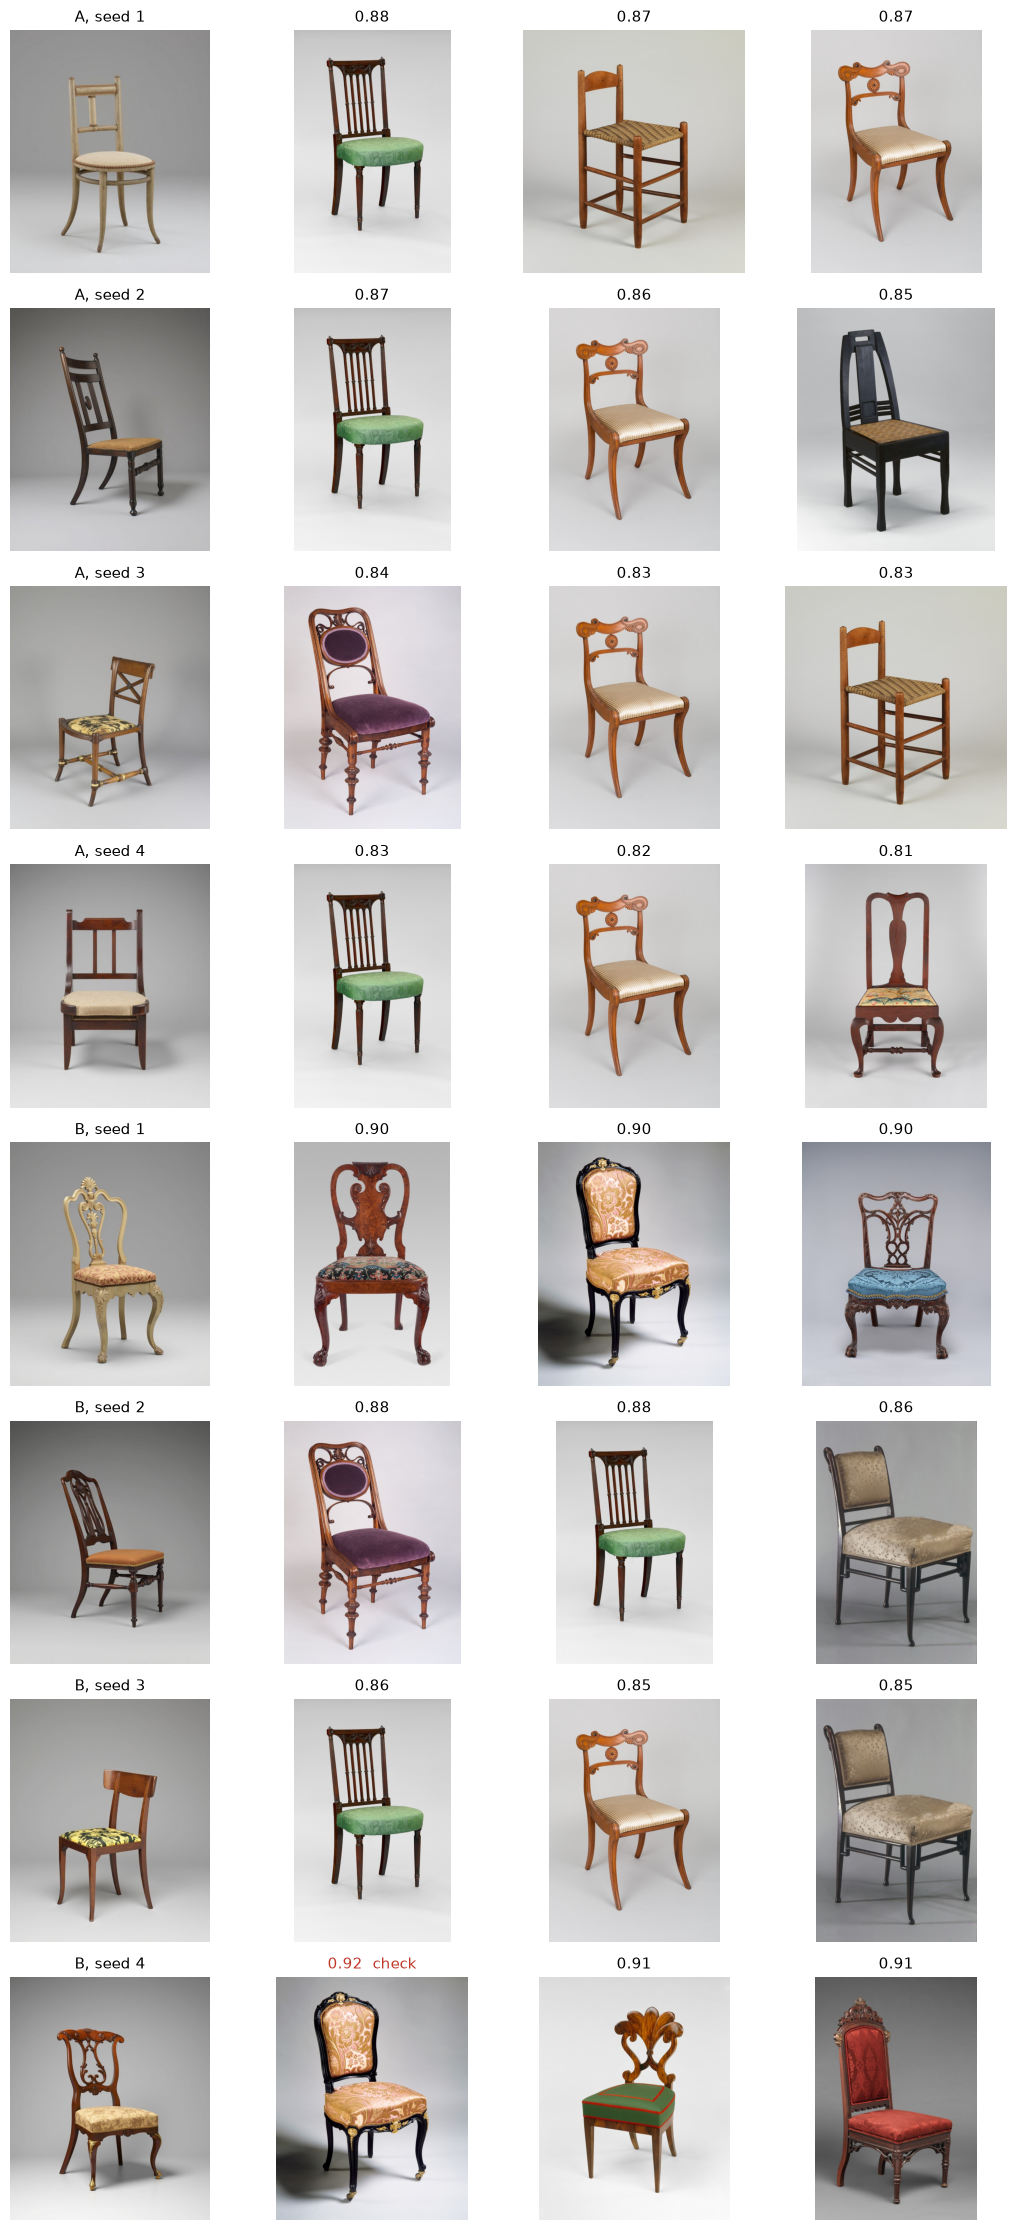

In [8]:
# DINOv2 is trained on images alone, and matches by how things look more closely than CLIP does.
from transformers import AutoImageProcessor, AutoModel
dproc = AutoImageProcessor.from_pretrained("facebook/dinov2-base")
dino = AutoModel.from_pretrained("facebook/dinov2-base").to(dev).eval()

def dino_embed(pics):
    out = []
    with torch.no_grad():
        for i in range(0, len(pics), 8):
            e = dino(**dproc(images=pics[i:i + 8], return_tensors="pt").to(dev)).pooler_output
            out.append(torch.nn.functional.normalize(e, dim=-1).cpu().numpy())
    return np.concatenate(out)

DT = dino_embed(train_pics)
TT = DT @ DT.T
np.fill_diagonal(TT, -1)
pair = TT.max(1)  # each training image and the training image closest to it
CHECK = np.percentile(pair, 95)
print(f"Each training image and its closest other training image: median {np.median(pair):.2f}, "
      f"and only 1 in 20 pairs above {CHECK:.2f}")
fig, axes = plt.subplots(2 * len(SEEDS), 4, figsize=(11, 5.6 * len(SEEDS)), squeeze=False)
r = 0
for label, pics in made.items():
    S = dino_embed(pics) @ DT.T
    flagged = 0
    for i, p in enumerate(pics):
        top = np.argsort(-S[i])[:3]
        flagged += S[i, top[0]] >= CHECK
        cells = [(p, f"{label}, seed {SEEDS[i]}", "black")] + [
            (train_pics[j], f"{S[i, j]:.2f}" + ("  check" if S[i, j] >= CHECK else ""),
             "#C0392B" if S[i, j] >= CHECK else "black") for j in top]
        for c, (im, title, color) in enumerate(cells):
            ax = axes[r, c]
            ax.imshow(im); ax.set_title(title, fontsize=11, color=color); ax.axis("off")
        r += 1
    print(f"{label}: {flagged} of {len(pics)} images have a training image above {CHECK:.2f}")
plt.tight_layout()
plt.savefig("closest.jpg", dpi=100)
plt.show()